In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = pd.read_csv("../datasets/netflix/netflix_titles.csv")

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Dataset loaded successfully!
Rows: 8807
Columns: 12


In [4]:
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB


In [8]:
# Check missing values
missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values[missing_values > 0])

Missing values in each column:
director      2634
cast           825
country        831
date_added      10
rating           4
duration         3
dtype: int64


In [9]:
# Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Check duplicate titles
print("Duplicate titles:", df["title"].duplicated().sum())

Duplicate rows: 0
Duplicate titles: 0


In [10]:
# Movies vs TV Shows
print("Content Type Distribution:")
print(df["type"].value_counts())

Content Type Distribution:
type
Movie      6131
TV Show    2676
Name: count, dtype: int64


In [11]:
# Release year statistics
print("Release Year Statistics:")
print(df["release_year"].describe())

Release Year Statistics:
count    8807.000000
mean     2014.180198
std         8.819312
min      1925.000000
25%      2013.000000
50%      2017.000000
75%      2019.000000
max      2021.000000
Name: release_year, dtype: float64


In [12]:
# Make a copy before cleaning
df_clean = df.copy()

# Fill missing values
df_clean["director"] = df_clean["director"].fillna("Unknown")
df_clean["cast"] = df_clean["cast"].fillna("Unknown")
df_clean["country"] = df_clean["country"].fillna("Unknown")
df_clean["date_added"] = df_clean["date_added"].fillna("Unknown")
df_clean["rating"] = df_clean["rating"].fillna("Unknown")
df_clean["duration"] = df_clean["duration"].fillna("Unknown")

print("Missing values after cleaning:")
print(df_clean.isnull().sum()[df_clean.isnull().sum() > 0])

Missing values after cleaning:
Series([], dtype: int64)


In [13]:
print("Duplicate rows after cleaning:", df_clean.duplicated().sum())

Duplicate rows after cleaning: 0


In [14]:
# Convert date_added to datetime
df_clean["date_added"] = pd.to_datetime(
    df_clean["date_added"],
    errors="coerce"
)

# Extract year and month
df_clean["added_year"] = df_clean["date_added"].dt.year
df_clean["added_month"] = df_clean["date_added"].dt.month

print(df_clean[["date_added", "added_year", "added_month"]].head())

  date_added  added_year  added_month
0 2021-09-25      2021.0          9.0
1 2021-09-24      2021.0          9.0
2 2021-09-24      2021.0          9.0
3 2021-09-24      2021.0          9.0
4 2021-09-24      2021.0          9.0


In [15]:
# Extract numeric duration
df_clean["duration_value"] = pd.to_numeric(
    df_clean["duration"].str.extract(r"(\d+)")[0],
    errors="coerce"
)

print(df_clean[["type", "duration", "duration_value"]].head(10))

      type   duration  duration_value
0    Movie     90 min            90.0
1  TV Show  2 Seasons             2.0
2  TV Show   1 Season             1.0
3  TV Show   1 Season             1.0
4  TV Show  2 Seasons             2.0
5  TV Show   1 Season             1.0
6    Movie     91 min            91.0
7    Movie    125 min           125.0
8  TV Show  9 Seasons             9.0
9    Movie    104 min           104.0


In [16]:
print("New columns:")
print(df_clean.columns.tolist())

New columns:
['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in', 'description', 'added_year', 'added_month', 'duration_value']


In [17]:
content_type = df_clean["type"].value_counts()

print("Content Type Distribution:")
print(content_type)

Content Type Distribution:
type
Movie      6131
TV Show    2676
Name: count, dtype: int64


In [18]:
content_percentage = (
    df_clean["type"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("Content Type Percentage:")
print(content_percentage)

Content Type Percentage:
type
Movie      69.62
TV Show    30.38
Name: proportion, dtype: float64


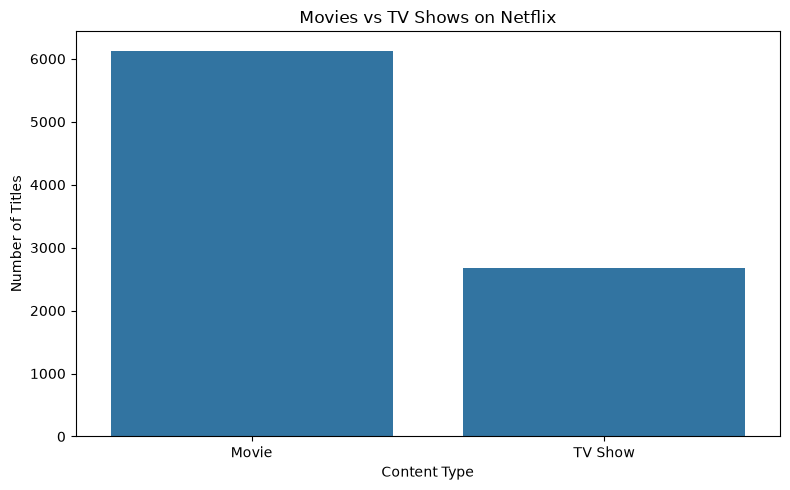

In [19]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=content_type.index,
    y=content_type.values
)

plt.title("Movies vs TV Shows on Netflix")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")

plt.tight_layout()
plt.savefig(
    "../outputs/netflix/movies_vs_tv_shows.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [20]:
added_year_counts = (
    df_clean["added_year"]
    .dropna()
    .astype(int)
    .value_counts()
    .sort_index()
)

print("Titles added by year:")
print(added_year_counts)

Titles added by year:
added_year
2008       2
2009       2
2010       1
2011      13
2012       3
2013      10
2014      23
2015      73
2016     418
2017    1164
2018    1625
2019    1999
2020    1878
2021    1498
Name: count, dtype: int64


In [22]:
most_added_year = added_year_counts.idxmax()
most_added_count = added_year_counts.max()

print("Year with most titles added:", most_added_year)
print("Number of titles added:", most_added_count)

Year with most titles added: 2019
Number of titles added: 1999


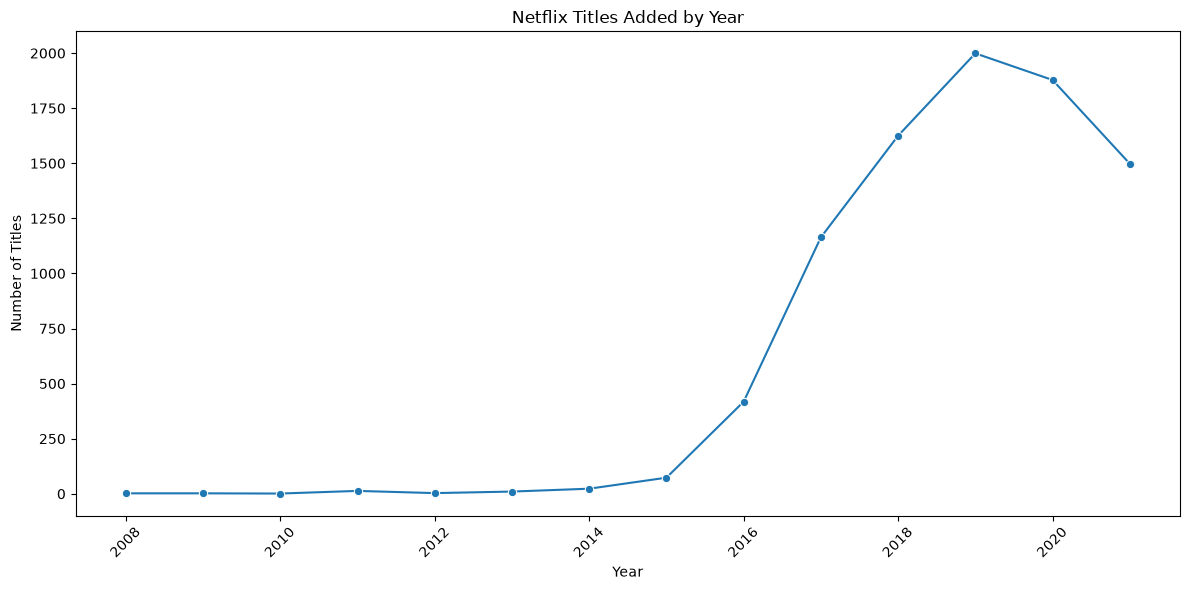

In [23]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    x=added_year_counts.index,
    y=added_year_counts.values,
    marker="o"
)

plt.title("Netflix Titles Added by Year")
plt.xlabel("Year")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig(
    "../outputs/netflix/titles_added_by_year.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [24]:
release_type = (
    df_clean.groupby(["release_year", "type"])
    .size()
    .reset_index(name="count")
)

print(release_type.head(10))

   release_year     type  count
0          1925  TV Show      1
1          1942    Movie      2
2          1943    Movie      3
3          1944    Movie      3
4          1945    Movie      3
5          1945  TV Show      1
6          1946    Movie      1
7          1946  TV Show      1
8          1947    Movie      1
9          1954    Movie      2


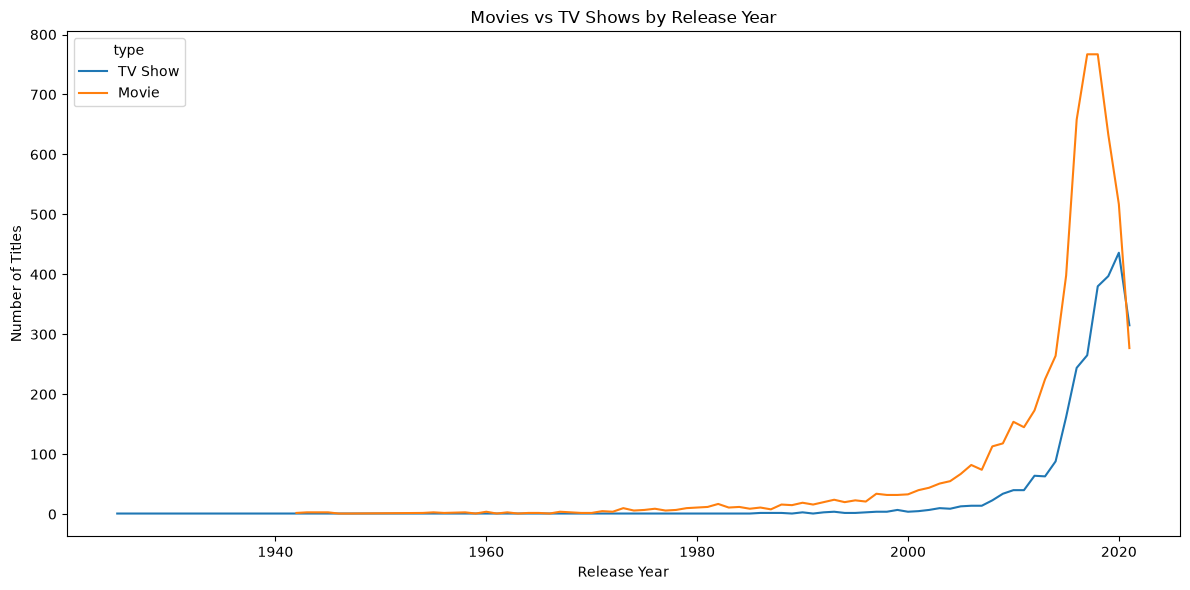

In [25]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=release_type,
    x="release_year",
    y="count",
    hue="type"
)

plt.title("Movies vs TV Shows by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")

plt.tight_layout()

plt.savefig(
    "../outputs/netflix/movies_vs_tv_by_release_year.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

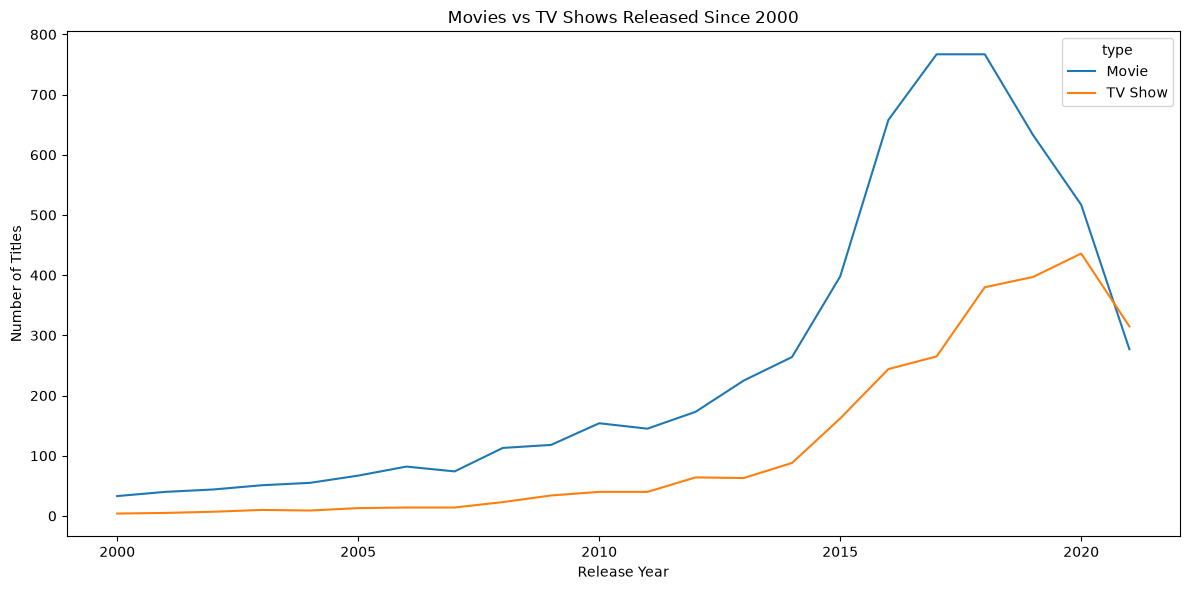

In [26]:
recent_release = df_clean[df_clean["release_year"] >= 2000]

recent_type = (
    recent_release.groupby(["release_year", "type"])
    .size()
    .reset_index(name="count")
)

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=recent_type,
    x="release_year",
    y="count",
    hue="type"
)

plt.title("Movies vs TV Shows Released Since 2000")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")

plt.tight_layout()

plt.savefig(
    "../outputs/netflix/movies_vs_tv_since_2000.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [27]:
rating_counts = df_clean["rating"].value_counts()

print("Netflix Rating Distribution:")
print(rating_counts)

Netflix Rating Distribution:
rating
TV-MA       3207
TV-14       2160
TV-PG        863
R            799
PG-13        490
TV-Y7        334
TV-Y         307
PG           287
TV-G         220
NR            80
G             41
TV-Y7-FV       6
Unknown        4
NC-17          3
UR             3
66 min         1
74 min         1
84 min         1
Name: count, dtype: int64


In [28]:
most_common_rating = rating_counts.idxmax()
most_common_count = rating_counts.max()

print("Most common rating:", most_common_rating)
print("Number of titles:", most_common_count)

Most common rating: TV-MA
Number of titles: 3207


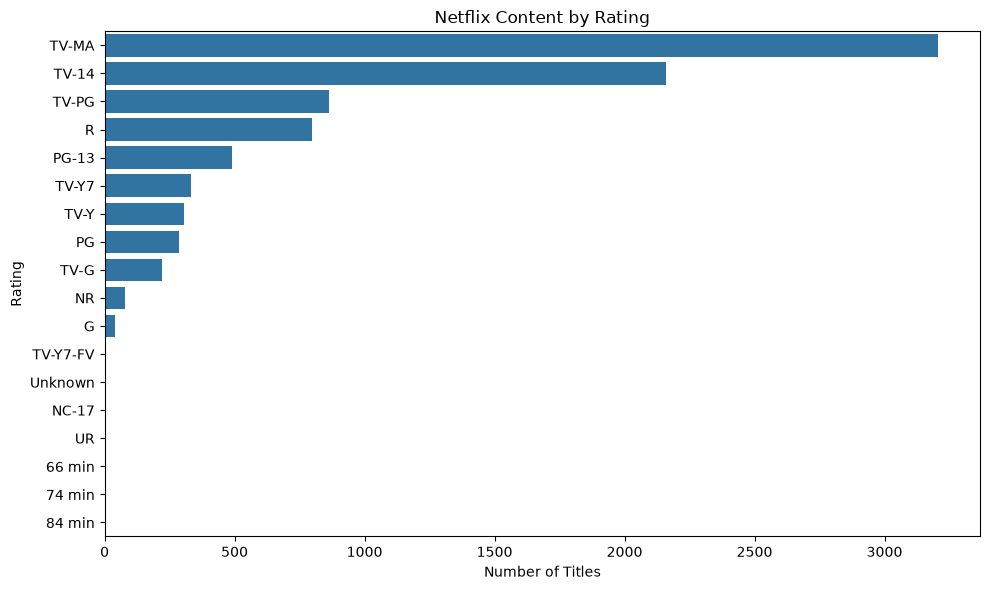

In [29]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=rating_counts.values,
    y=rating_counts.index
)

plt.title("Netflix Content by Rating")
plt.xlabel("Number of Titles")
plt.ylabel("Rating")

plt.tight_layout()

plt.savefig(
    "../outputs/netflix/rating_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [30]:
rating_by_type = (
    df_clean.groupby(["rating", "type"])
    .size()
    .reset_index(name="count")
)

print(rating_by_type.head(20))

    rating     type  count
0   66 min    Movie      1
1   74 min    Movie      1
2   84 min    Movie      1
3        G    Movie     41
4    NC-17    Movie      3
5       NR    Movie     75
6       NR  TV Show      5
7       PG    Movie    287
8    PG-13    Movie    490
9        R    Movie    797
10       R  TV Show      2
11   TV-14    Movie   1427
12   TV-14  TV Show    733
13    TV-G    Movie    126
14    TV-G  TV Show     94
15   TV-MA    Movie   2062
16   TV-MA  TV Show   1145
17   TV-PG    Movie    540
18   TV-PG  TV Show    323
19    TV-Y    Movie    131


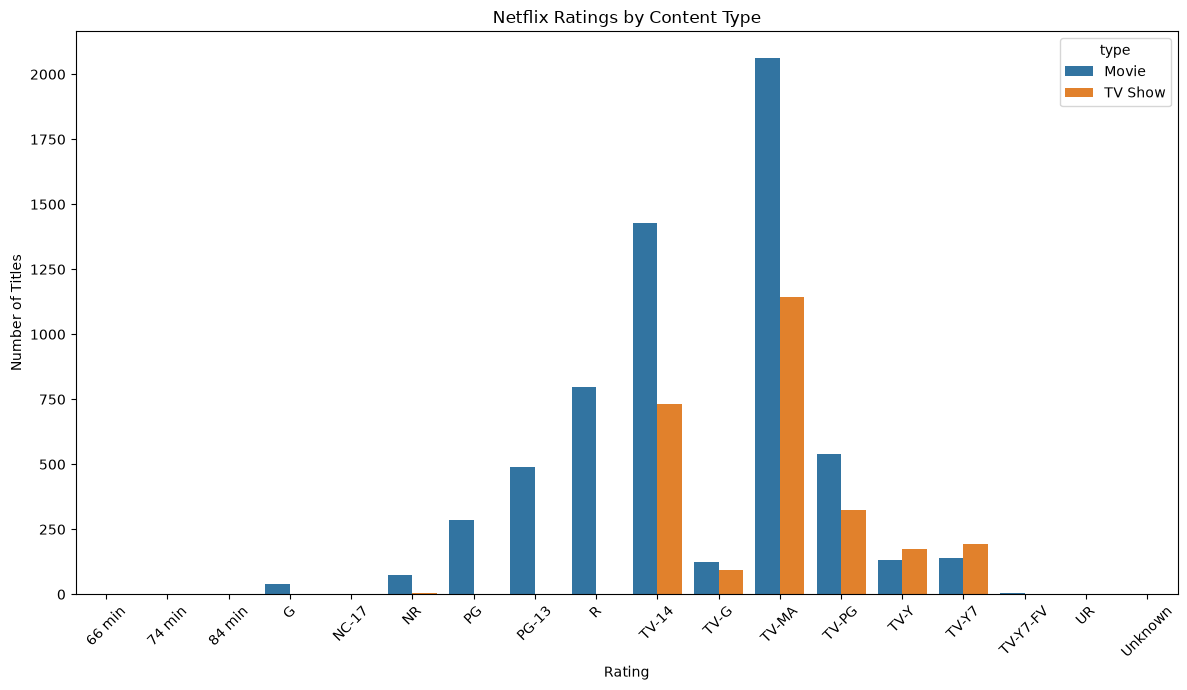

In [31]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=rating_by_type,
    x="rating",
    y="count",
    hue="type"
)

plt.title("Netflix Ratings by Content Type")
plt.xlabel("Rating")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig(
    "../outputs/netflix/ratings_by_content_type.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [32]:
valid_ratings = [
    "TV-MA", "TV-14", "TV-PG", "R", "PG-13",
    "TV-Y7", "TV-Y", "PG", "TV-G", "NR",
    "G", "TV-Y7-FV", "NC-17", "UR"
]

rating_clean = df_clean[
    df_clean["rating"].isin(valid_ratings)
]

rating_type_clean = (
    rating_clean.groupby(["rating", "type"])
    .size()
    .reset_index(name="count")
)

print(rating_type_clean)

      rating     type  count
0          G    Movie     41
1      NC-17    Movie      3
2         NR    Movie     75
3         NR  TV Show      5
4         PG    Movie    287
5      PG-13    Movie    490
6          R    Movie    797
7          R  TV Show      2
8      TV-14    Movie   1427
9      TV-14  TV Show    733
10      TV-G    Movie    126
11      TV-G  TV Show     94
12     TV-MA    Movie   2062
13     TV-MA  TV Show   1145
14     TV-PG    Movie    540
15     TV-PG  TV Show    323
16      TV-Y    Movie    131
17      TV-Y  TV Show    176
18     TV-Y7    Movie    139
19     TV-Y7  TV Show    195
20  TV-Y7-FV    Movie      5
21  TV-Y7-FV  TV Show      1
22        UR    Movie      3


In [33]:
country_data = df_clean[df_clean["country"] != "Unknown"].copy()

country_data["country"] = country_data["country"].str.split(", ")

country_data = country_data.explode("country")

country_counts = country_data["country"].value_counts()

print("Top 15 countries by Netflix content:")
print(country_counts.head(15))

Top 15 countries by Netflix content:
country
United States     3689
India             1046
United Kingdom     804
Canada             445
France             393
Japan              318
Spain              232
South Korea        231
Germany            226
Mexico             169
China              162
Australia          160
Egypt              117
Turkey             113
Hong Kong          105
Name: count, dtype: int64


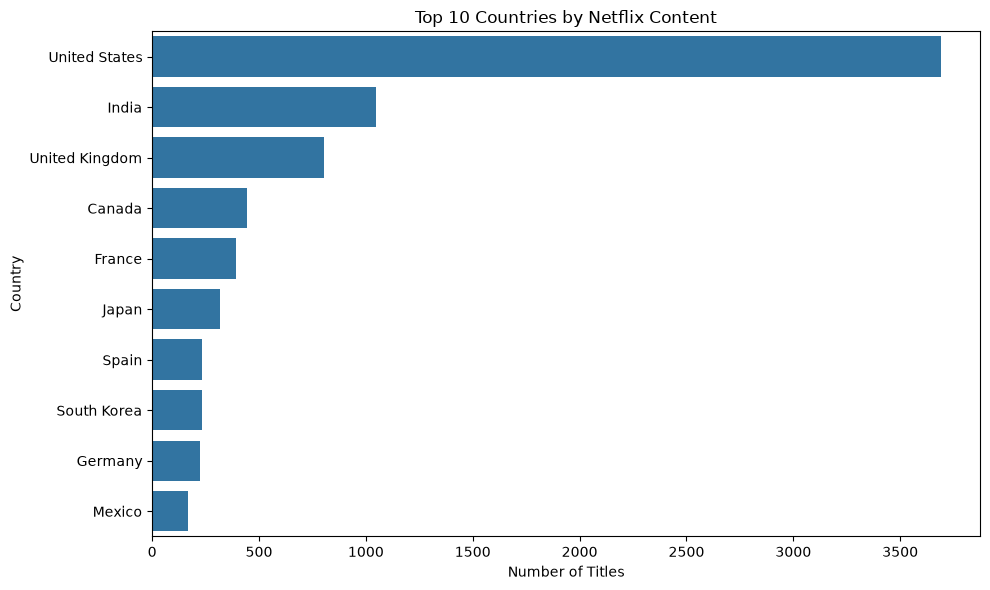

In [35]:
top_countries = country_counts.head(10)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_countries.values,
    y=top_countries.index
)

plt.title("Top 10 Countries by Netflix Content")
plt.xlabel("Number of Titles")
plt.ylabel("Country")

plt.tight_layout()

plt.savefig(
    "../outputs/netflix/top_10_countries.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [37]:
genre_data = df_clean.copy()

genre_data["genre"] = genre_data["listed_in"].str.split(", ")

genre_data = genre_data.explode("genre")

genre_counts = genre_data["genre"].value_counts()

print("Top 15 Netflix genres:")
print(genre_counts.head(15))

Top 15 Netflix genres:
genre
International Movies        2752
Dramas                      2427
Comedies                    1674
International TV Shows      1351
Documentaries                869
Action & Adventure           859
TV Dramas                    763
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
TV Comedies                  581
Thrillers                    577
Crime TV Shows               470
Kids' TV                     451
Docuseries                   395
Name: count, dtype: int64


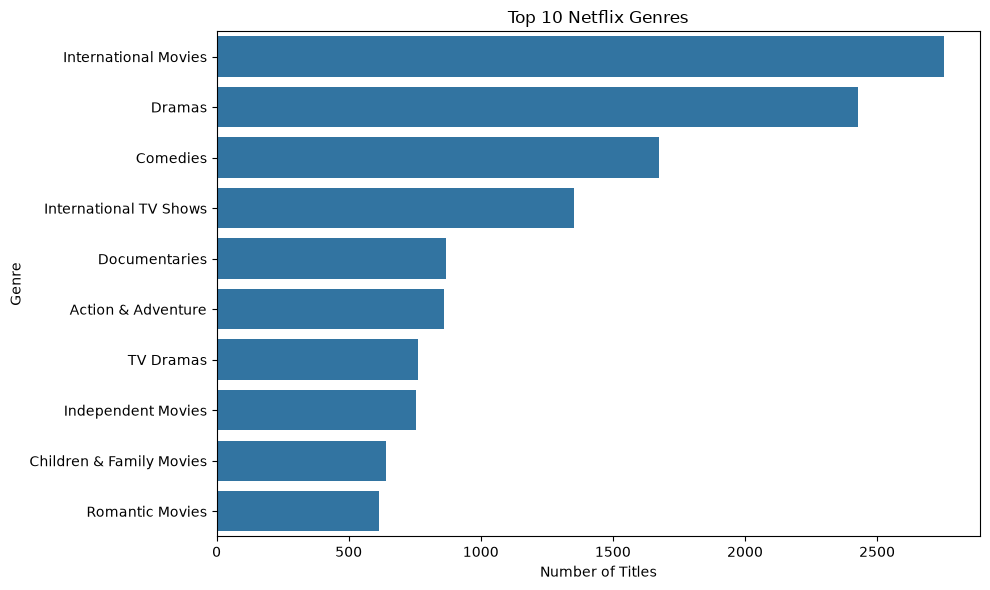

In [38]:
top_genres = genre_counts.head(10)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_genres.values,
    y=top_genres.index
)

plt.title("Top 10 Netflix Genres")
plt.xlabel("Number of Titles")
plt.ylabel("Genre")

plt.tight_layout()

plt.savefig(
    "../outputs/netflix/top_10_genres.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [39]:
movie_duration = df_clean[
    df_clean["type"] == "Movie"
].copy()

print("Movie Duration Statistics:")
print(movie_duration["duration_value"].describe())

Movie Duration Statistics:
count    6128.000000
mean       99.577187
std        28.290593
min         3.000000
25%        87.000000
50%        98.000000
75%       114.000000
max       312.000000
Name: duration_value, dtype: float64


In [41]:
average_duration = movie_duration["duration_value"].mean()
shortest_movie = movie_duration["duration_value"].min()
longest_movie = movie_duration["duration_value"].max()

print("Average movie duration:", round(average_duration, 2), "minutes")
print("Shortest movie:", shortest_movie, "minutes")
print("Longest movie:", longest_movie, "minutes")

Average movie duration: 99.58 minutes
Shortest movie: 3.0 minutes
Longest movie: 312.0 minutes


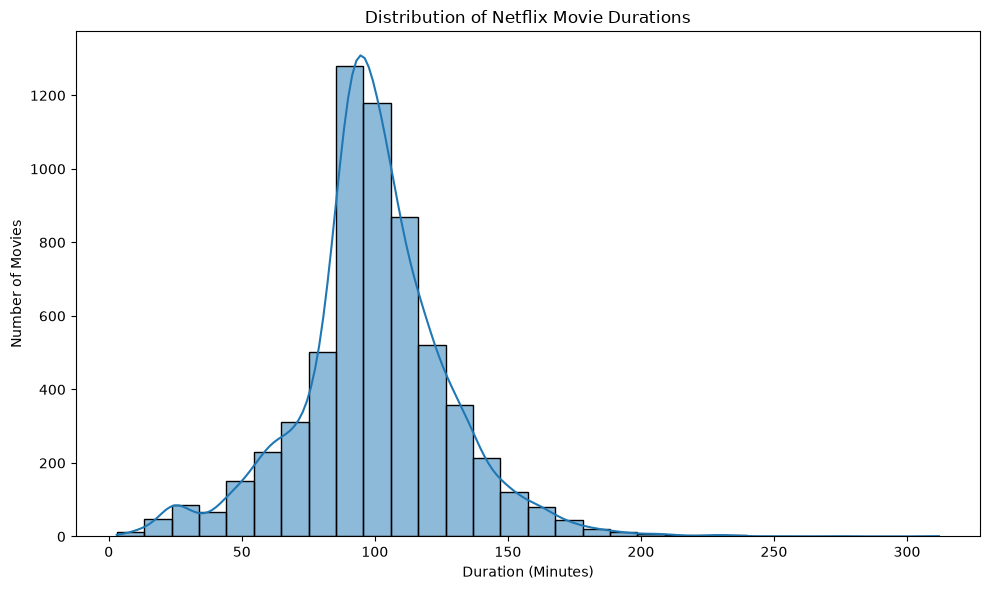

In [42]:
plt.figure(figsize=(10, 6))

sns.histplot(
    movie_duration["duration_value"],
    bins=30,
    kde=True
)

plt.title("Distribution of Netflix Movie Durations")
plt.xlabel("Duration (Minutes)")
plt.ylabel("Number of Movies")

plt.tight_layout()

plt.savefig(
    "../outputs/netflix/movie_duration_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [43]:
tv_duration = df_clean[
    df_clean["type"] == "TV Show"
].copy()

print("TV Show Season Statistics:")
print(tv_duration["duration_value"].describe())

TV Show Season Statistics:
count    2676.000000
mean        1.764948
std         1.582752
min         1.000000
25%         1.000000
50%         1.000000
75%         2.000000
max        17.000000
Name: duration_value, dtype: float64


In [44]:
average_seasons = tv_duration["duration_value"].mean()
min_seasons = tv_duration["duration_value"].min()
max_seasons = tv_duration["duration_value"].max()

print("Average seasons:", round(average_seasons, 2))
print("Minimum seasons:", min_seasons)
print("Maximum seasons:", max_seasons)

Average seasons: 1.76
Minimum seasons: 1.0
Maximum seasons: 17.0


In [45]:
season_counts = tv_duration["duration_value"].value_counts().sort_index()

print("TV Shows by number of seasons:")
print(season_counts)

TV Shows by number of seasons:
duration_value
1.0     1793
2.0      425
3.0      199
4.0       95
5.0       65
6.0       33
7.0       23
8.0       17
9.0        9
10.0       7
11.0       2
12.0       2
13.0       3
15.0       2
17.0       1
Name: count, dtype: int64


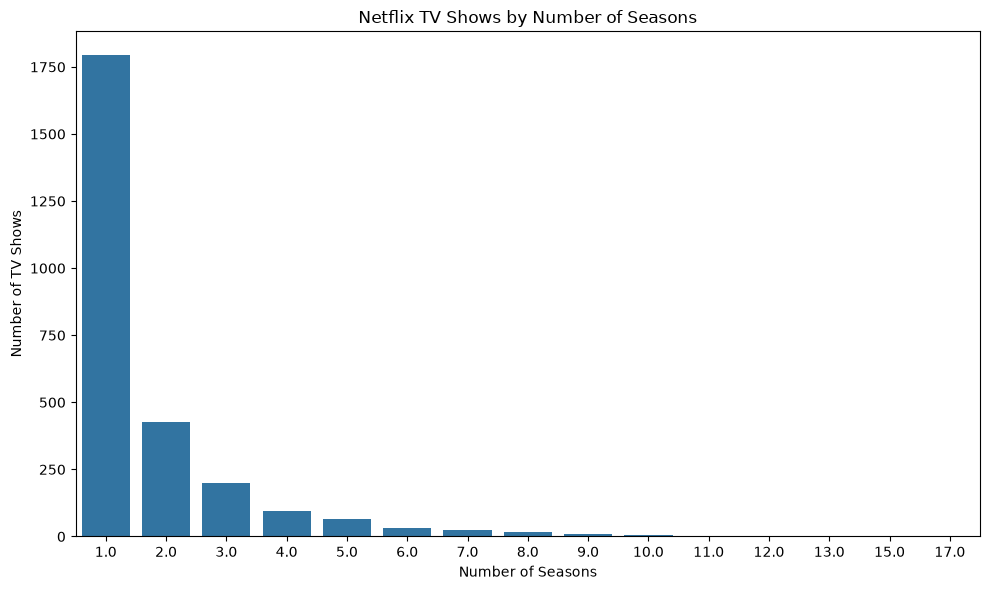

In [46]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=season_counts.index,
    y=season_counts.values
)

plt.title("Netflix TV Shows by Number of Seasons")
plt.xlabel("Number of Seasons")
plt.ylabel("Number of TV Shows")

plt.tight_layout()

plt.savefig(
    "../outputs/netflix/tv_show_seasons.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [47]:
director_data = df_clean[
    df_clean["director"] != "Unknown"
].copy()

director_data["director"] = director_data["director"].str.split(", ")

director_data = director_data.explode("director")

director_counts = director_data["director"].value_counts()

print("Top 15 Netflix directors:")
print(director_counts.head(15))

Top 15 Netflix directors:
director
Rajiv Chilaka          22
Jan Suter              21
Raúl Campos            19
Marcus Raboy           16
Suhas Kadav            16
Jay Karas              15
Cathy Garcia-Molina    13
Youssef Chahine        12
Martin Scorsese        12
Jay Chapman            12
Steven Spielberg       11
Don Michael Paul       10
David Dhawan            9
Yılmaz Erdoğan          9
Shannon Hartman         9
Name: count, dtype: int64


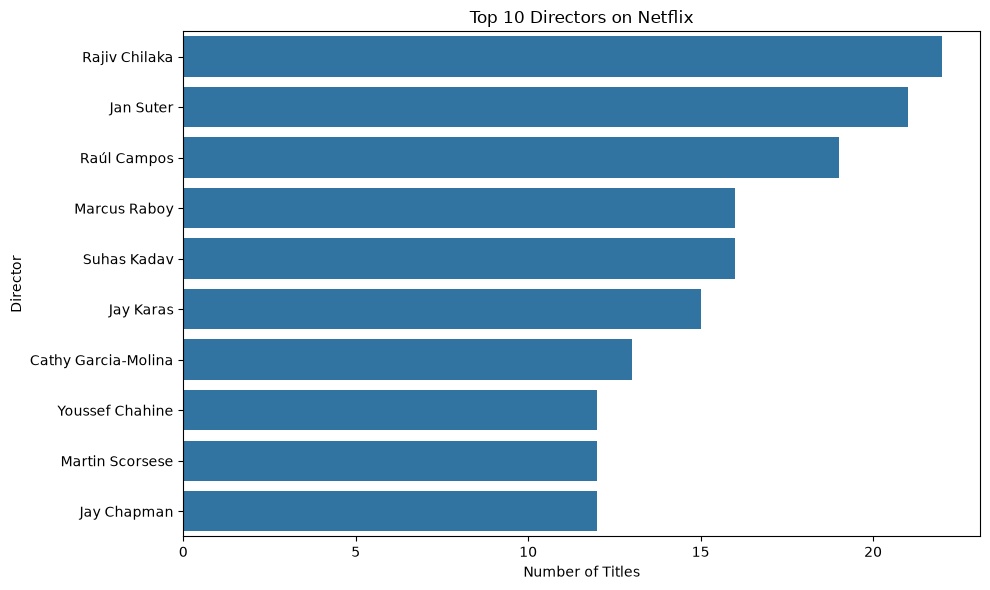

In [48]:
top_directors = director_counts.head(10)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_directors.values,
    y=top_directors.index
)

plt.title("Top 10 Directors on Netflix")
plt.xlabel("Number of Titles")
plt.ylabel("Director")

plt.tight_layout()

plt.savefig(
    "../outputs/netflix/top_10_directors.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [49]:
cast_data = df_clean[
    df_clean["cast"] != "Unknown"
].copy()

cast_data["cast"] = cast_data["cast"].str.split(", ")

cast_data = cast_data.explode("cast")

cast_counts = cast_data["cast"].value_counts()

print("Top 15 Netflix actors:")
print(cast_counts.head(15))

Top 15 Netflix actors:
cast
Anupam Kher         43
Shah Rukh Khan      35
Julie Tejwani       33
Takahiro Sakurai    32
Naseeruddin Shah    32
Rupa Bhimani        31
Om Puri             30
Akshay Kumar        30
Yuki Kaji           29
Amitabh Bachchan    28
Paresh Rawal        28
Boman Irani         27
Rajesh Kava         26
Vincent Tong        26
Andrea Libman       25
Name: count, dtype: int64


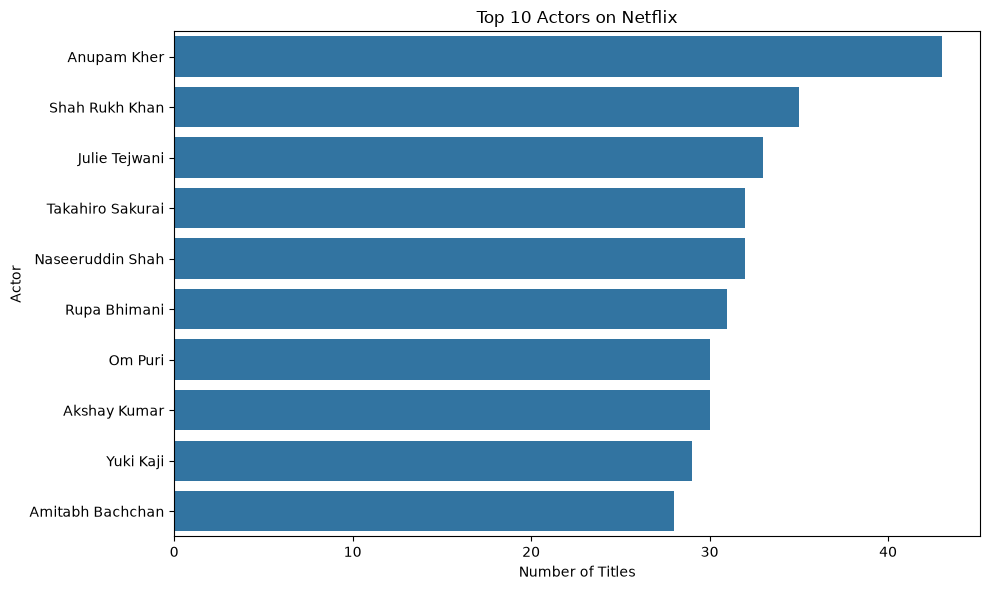

In [50]:
top_cast = cast_counts.head(10)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_cast.values,
    y=top_cast.index
)

plt.title("Top 10 Actors on Netflix")
plt.xlabel("Number of Titles")
plt.ylabel("Actor")

plt.tight_layout()

plt.savefig(
    "../outputs/netflix/top_10_actors.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [51]:
content_by_year = df_clean[
    df_clean["added_year"].notna()
].groupby(
    ["added_year", "type"]
).size().reset_index(name="count")

print(content_by_year)

    added_year     type  count
0       2008.0    Movie      1
1       2008.0  TV Show      1
2       2009.0    Movie      2
3       2010.0    Movie      1
4       2011.0    Movie     13
5       2012.0    Movie      3
6       2013.0    Movie      6
7       2013.0  TV Show      4
8       2014.0    Movie     19
9       2014.0  TV Show      4
10      2015.0    Movie     56
11      2015.0  TV Show     17
12      2016.0    Movie    253
13      2016.0  TV Show    165
14      2017.0    Movie    839
15      2017.0  TV Show    325
16      2018.0    Movie   1237
17      2018.0  TV Show    388
18      2019.0    Movie   1424
19      2019.0  TV Show    575
20      2020.0    Movie   1284
21      2020.0  TV Show    594
22      2021.0    Movie    993
23      2021.0  TV Show    505


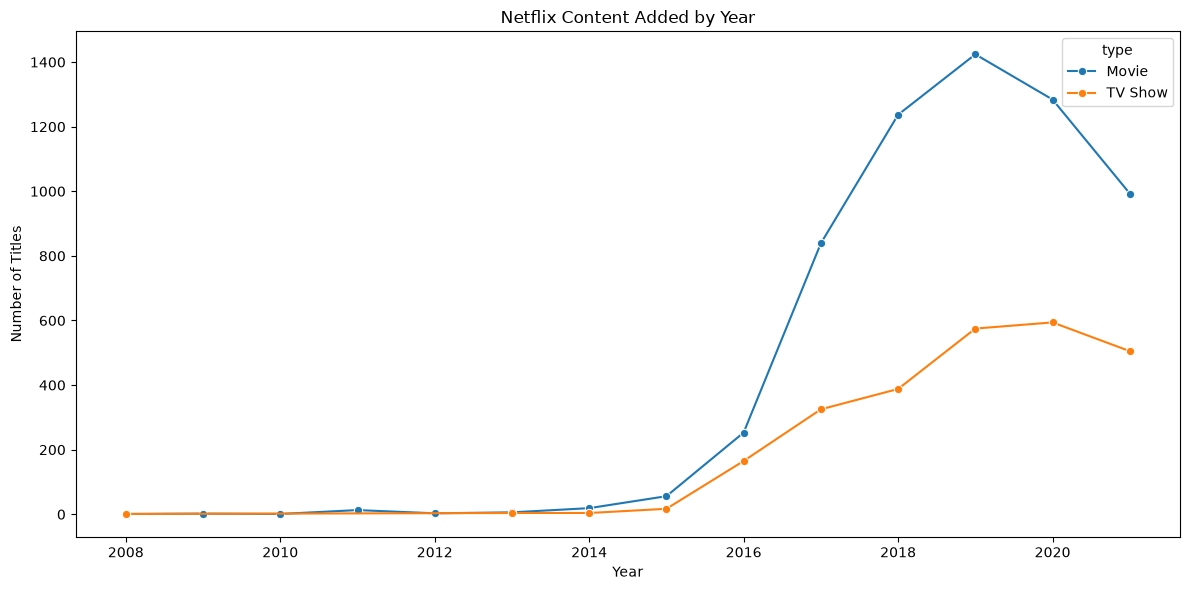

In [52]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=content_by_year,
    x="added_year",
    y="count",
    hue="type",
    marker="o"
)

plt.title("Netflix Content Added by Year")
plt.xlabel("Year")
plt.ylabel("Number of Titles")

plt.tight_layout()

plt.savefig(
    "../outputs/netflix/content_growth_by_year.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [53]:
movie_peak = content_by_year[
    content_by_year["type"] == "Movie"
].loc[
    lambda x: x["count"].idxmax()
]

tv_peak = content_by_year[
    content_by_year["type"] == "TV Show"
].loc[
    lambda x: x["count"].idxmax()
]

print("Peak Movie addition year:")
print(movie_peak)

print("\nPeak TV Show addition year:")
print(tv_peak)

Peak Movie addition year:
added_year    2019.0
type           Movie
count           1424
Name: 18, dtype: object

Peak TV Show addition year:
added_year     2020.0
type          TV Show
count             594
Name: 21, dtype: object


In [54]:
release_by_year = (
    df_clean.groupby(["release_year", "type"])
    .size()
    .reset_index(name="count")
)

print(release_by_year.head(20))

    release_year     type  count
0           1925  TV Show      1
1           1942    Movie      2
2           1943    Movie      3
3           1944    Movie      3
4           1945    Movie      3
5           1945  TV Show      1
6           1946    Movie      1
7           1946  TV Show      1
8           1947    Movie      1
9           1954    Movie      2
10          1955    Movie      3
11          1956    Movie      2
12          1958    Movie      3
13          1959    Movie      1
14          1960    Movie      4
15          1961    Movie      1
16          1962    Movie      3
17          1963    Movie      1
18          1963  TV Show      1
19          1964    Movie      2


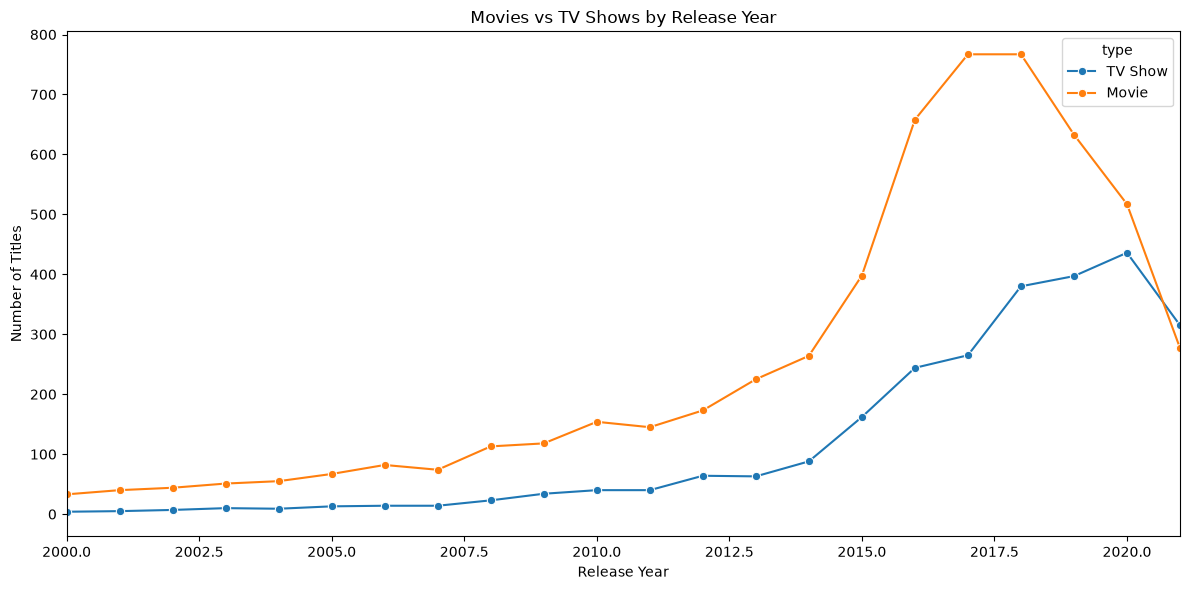

In [55]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=release_by_year,
    x="release_year",
    y="count",
    hue="type",
    marker="o"
)

plt.title("Movies vs TV Shows by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")

plt.xlim(2000, 2021)

plt.tight_layout()

plt.savefig(
    "../outputs/netflix/movies_vs_tvshows_release_year.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [56]:
movie_release_peak = release_by_year[
    release_by_year["type"] == "Movie"
].loc[
    lambda x: x["count"].idxmax()
]

tv_release_peak = release_by_year[
    release_by_year["type"] == "TV Show"
].loc[
    lambda x: x["count"].idxmax()
]

print("Peak Movie release year:")
print(movie_release_peak)

print("\nPeak TV Show release year:")
print(tv_release_peak)

Peak Movie release year:
release_year     2017
type            Movie
count             767
Name: 109, dtype: object

Peak TV Show release year:
release_year       2020
type            TV Show
count               436
Name: 116, dtype: object


In [57]:
monthly_content = (
    df_clean[df_clean["added_month"].notna()]
    .groupby("added_month")
    .size()
)

print("Content added by month:")
print(monthly_content)

Content added by month:
added_month
1.0     727
2.0     557
3.0     734
4.0     759
5.0     626
6.0     724
7.0     819
8.0     749
9.0     765
10.0    755
11.0    697
12.0    797
dtype: int64


In [58]:
month_names = {
    1: "January",
    2: "February",
    3: "March",
    4: "April",
    5: "May",
    6: "June",
    7: "July",
    8: "August",
    9: "September",
    10: "October",
    11: "November",
    12: "December"
}

monthly_content.index = monthly_content.index.map(
    lambda x: month_names[int(x)]
)

print("\nContent added by month:")
print(monthly_content)


Content added by month:
added_month
January      727
February     557
March        734
April        759
May          626
June         724
July         819
August       749
September    765
October      755
November     697
December     797
dtype: int64


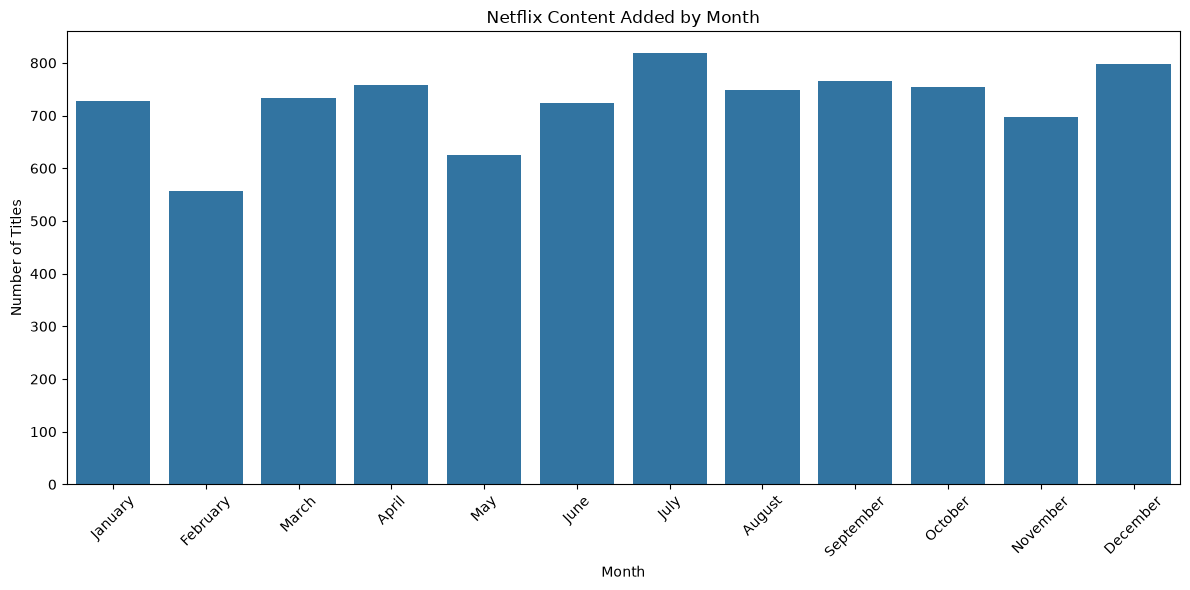

In [59]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=monthly_content.index,
    y=monthly_content.values
)

plt.title("Netflix Content Added by Month")
plt.xlabel("Month")
plt.ylabel("Number of Titles")

plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig(
    "../outputs/netflix/monthly_content_additions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [60]:
most_active_month = monthly_content.idxmax()
most_active_count = monthly_content.max()

print(
    "Month with most content added:",
    most_active_month
)

print(
    "Number of titles added:",
    most_active_count
)

Month with most content added: July
Number of titles added: 819


In [61]:
rating_type = (
    rating_clean.groupby(["rating", "type"])
    .size()
    .reset_index(name="count")
)

print(rating_type)

      rating     type  count
0          G    Movie     41
1      NC-17    Movie      3
2         NR    Movie     75
3         NR  TV Show      5
4         PG    Movie    287
5      PG-13    Movie    490
6          R    Movie    797
7          R  TV Show      2
8      TV-14    Movie   1427
9      TV-14  TV Show    733
10      TV-G    Movie    126
11      TV-G  TV Show     94
12     TV-MA    Movie   2062
13     TV-MA  TV Show   1145
14     TV-PG    Movie    540
15     TV-PG  TV Show    323
16      TV-Y    Movie    131
17      TV-Y  TV Show    176
18     TV-Y7    Movie    139
19     TV-Y7  TV Show    195
20  TV-Y7-FV    Movie      5
21  TV-Y7-FV  TV Show      1
22        UR    Movie      3


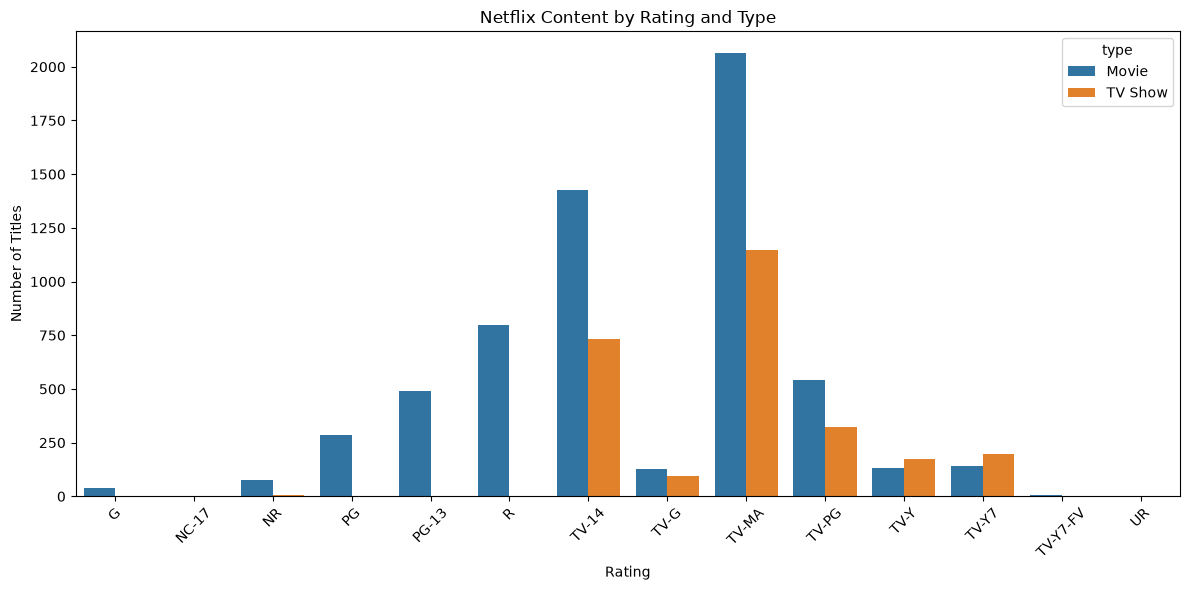

In [62]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=rating_type,
    x="rating",
    y="count",
    hue="type"
)

plt.title("Netflix Content by Rating and Type")
plt.xlabel("Rating")
plt.ylabel("Number of Titles")

plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig(
    "../outputs/netflix/rating_by_content_type.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [63]:
dominant_rating = (
    rating_type.loc[
        rating_type.groupby("type")["count"].idxmax()
    ]
)

print("Most common rating by content type:")
print(dominant_rating)

Most common rating by content type:
   rating     type  count
12  TV-MA    Movie   2062
13  TV-MA  TV Show   1145


In [64]:
print("=" * 50)
print("       NETFLIX CONTENT ANALYSIS SUMMARY")
print("=" * 50)

print(f"Total Titles: {len(df_clean)}")
print(f"Movies: {(df_clean['type'] == 'Movie').sum()}")
print(f"TV Shows: {(df_clean['type'] == 'TV Show').sum()}")

print("\n--- Content Distribution ---")
print(df_clean["type"].value_counts())

print("\n--- Top Country ---")
print(country_counts.head(5))

print("\n--- Top Genres ---")
print(genre_counts.head(5))

print("\n--- Movie Duration ---")
print(f"Average: {movie_duration['duration_value'].mean():.2f} minutes")
print(f"Shortest: {movie_duration['duration_value'].min():.0f} minutes")
print(f"Longest: {movie_duration['duration_value'].max():.0f} minutes")

print("\n--- TV Show Seasons ---")
print(f"Average: {tv_duration['duration_value'].mean():.2f} seasons")
print(f"Maximum: {tv_duration['duration_value'].max():.0f} seasons")

print("\n--- Top Directors ---")
print(director_counts.head(5))

print("\n--- Top Actors ---")
print(cast_counts.head(5))

print("\n--- Content Growth ---")
print("Peak Movie Addition Year: 2019")
print("Peak TV Show Addition Year: 2020")

print("\n--- Monthly Additions ---")
print(f"Most Active Month: {most_active_month}")
print(f"Titles Added: {most_active_count}")

print("\n--- Most Common Rating ---")
print("Movies: TV-MA")
print("TV Shows: TV-MA")

print("=" * 50)

       NETFLIX CONTENT ANALYSIS SUMMARY
Total Titles: 8807
Movies: 6131
TV Shows: 2676

--- Content Distribution ---
type
Movie      6131
TV Show    2676
Name: count, dtype: int64

--- Top Country ---
country
United States     3689
India             1046
United Kingdom     804
Canada             445
France             393
Name: count, dtype: int64

--- Top Genres ---
genre
International Movies      2752
Dramas                    2427
Comedies                  1674
International TV Shows    1351
Documentaries              869
Name: count, dtype: int64

--- Movie Duration ---
Average: 99.58 minutes
Shortest: 3 minutes
Longest: 312 minutes

--- TV Show Seasons ---
Average: 1.76 seasons
Maximum: 17 seasons

--- Top Directors ---
director
Rajiv Chilaka    22
Jan Suter        21
Raúl Campos      19
Marcus Raboy     16
Suhas Kadav      16
Name: count, dtype: int64

--- Top Actors ---
cast
Anupam Kher         43
Shah Rukh Khan      35
Julie Tejwani       33
Takahiro Sakurai    32
Naseeruddin S